In [ ]:

"""
Figure 6 - Ice surface velocity at LEV6 and KAN_U between 2009-2012 and 2021-2023, with seasonal velocities shown. 
Author: Hannah Picton 
Date: 27th March 2026
Description: This notebook plots ice surface velocity at (a) LEV6 and (b) KAN_U between 2009-2012 and 2021-2023. Ice surface velocity data for 2009-2012 can be found at Tedstone & Nienow (2018; https://doi.org/10.5285/1f69fba3-4c62-47ad-8119-08cfeec05e46) and for 2021-2023 at Tedstone et al. (2026; https://doi.org/10.5281/zenodo.18611668). Note that seasonal components at KAN_U between 2009-2012 are taken from Doyle et al. (2014).
"""

# Import libraries 
import os
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np
import glob

# -- PROVIDE PATH TO ICE DISPLACEMENT DATA (LEV6 & KANU) --
velocity_data_path = '.../data' # UPDATE FILEPATH
velocity_folders = ['seasonal_annual_2009_2013', 'seasonal_annual_2020_2024']

# Define plot colours and shared plotting parameters
palette = {'Summer': '#219ebc','Winter': '#126782', 'Annual': '#14213d'}
years_disp = [2009, 2010, 2011, 2012, 2021, 2022, 2023]
mapped_years_disp = [0, 1, 2, 3, 4.5, 5.5, 6.5]
year_mapping_disp = dict(zip(years_disp, mapped_years_disp))

def plot_velocity_site(ax, site_code, plot_label, ylim_range, data_col='vel_m_yr'):
    store = []
    for folder in velocity_folders:
        fglob = os.path.join(velocity_data_path, folder, f'{site_code}_seasonal_annual_*.csv')
        files = glob.glob(fglob)
        for fs in files:
            store.append(pd.read_csv(fs))
    df = pd.concat(store, axis=0)
    df = df[df['period'].isin(['Summer', 'Winter', 'Annual'])]
    df = df[df['year'].isin(years_disp)]
    df['mapped_year'] = df['year'].map(year_mapping_disp)
    pivoted = df.pivot(index='mapped_year', columns='period', values=data_col)

    # Group bars and define offsets: Summer (Left), Winter (Center), Annual (Right)
    bar_width = 0.27
    x_indices = pivoted.index
    x_summer = x_indices - bar_width
    x_winter = x_indices
    x_annual = x_indices + bar_width

    # Plot Bars (Check if column exists to avoid errors if data is missing)
    if 'Summer' in pivoted.columns:
        ax.bar(x_summer, pivoted['Summer'], width=bar_width, color=palette['Summer'], alpha = 0.55,label='Summer', edgecolor='white', linewidth=0.9, zorder=3)
    if 'Winter' in pivoted.columns: 
        ax.bar(x_winter, pivoted['Winter'], width=bar_width, color=palette['Winter'], alpha = 0.85, label='Winter', edgecolor='white', linewidth=0.9, zorder=3)
    if 'Annual' in pivoted.columns:
        ax.bar(x_annual, pivoted['Annual'], width=bar_width, color=palette['Annual'], label='Annual',  edgecolor='white', linewidth=0.9, zorder=3)

    ax.set_xticks(mapped_years_disp)
    ax.set_ylim(ylim_range)
    ax.set_ylabel('Velocity (m yr$^{-1}$)', fontsize=10, labelpad=10)
    ax.grid(axis='y', linestyle='-', alpha=0.2, zorder=0)
    ax.set_xlim(-0.8, 7.3)
    ax.text(0.04, 0.9, plot_label, transform=ax.transAxes, fontsize=14, fontweight='bold', ha='left', va='top', color='black')

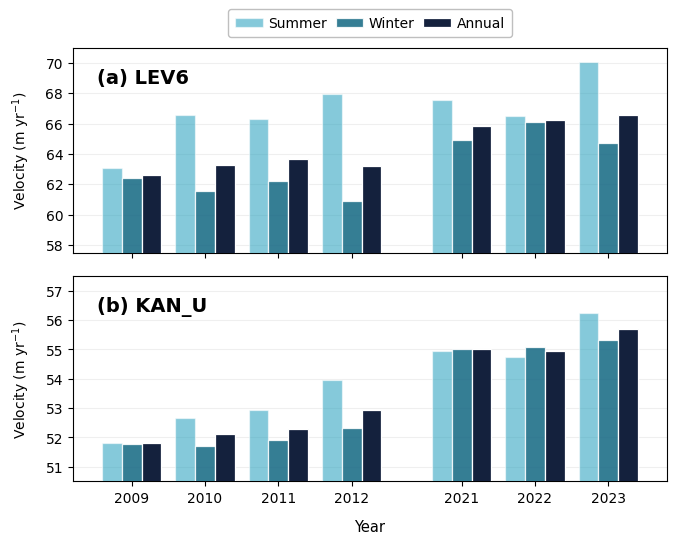

In [2]:
# Plot ice surface velocity at LEV6 and KAN_U between 2009-2012 and 2021-2023, with seasonal velocities shown. 
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 5.5))
plt.subplots_adjust(hspace=0.3)

# --- (a) LEV6 ---
plot_velocity_site(ax1, 'lev6', '(a) LEV6', (57.5, 71), data_col='vel_m_yr')
handles, labels = ax1.get_legend_handles_labels()
order = ['Summer', 'Winter', 'Annual']
handle_dict = dict(zip(labels, handles))
sorted_handles = [handle_dict[l] for l in order if l in handle_dict]
sorted_labels = [l for l in order if l in handle_dict]
ax1.legend(handles=sorted_handles, labels=sorted_labels,loc='upper center', bbox_to_anchor=(0.5, 1.22), borderpad=0.5,
           fontsize=10, ncol=3, columnspacing=0.6, handletextpad=0.4, facecolor='white', framealpha=0.5, edgecolor='grey')
ax1.set_xticklabels([])

# --- (b) KANU ---
plot_velocity_site(ax2, 'kanu', '(b) KAN_U', (50.5, 57.5), data_col='vel_m_yr')
ax2.set_xticklabels(years_disp, fontsize=10)
ax2.set_xlabel('Year', fontsize=10.5, labelpad=10)

plt.tight_layout()
plt.show()